<a href="https://colab.research.google.com/github/AdityaJare/ML-PRojects/blob/main/mnist_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
y_train.shape

(60000,)

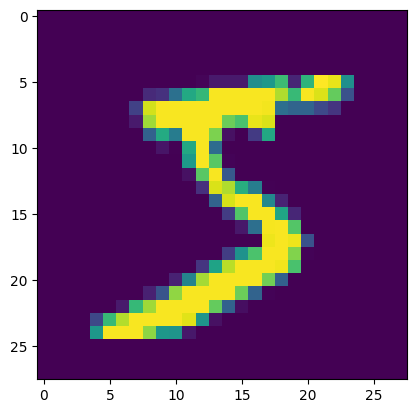

In [5]:
import matplotlib.pyplot as plt
plt.imshow(x_train[0])

In [18]:
from numpy import float32
x_train  = x_train.astype(float32) / 255.
x_test = x_test.astype(float32) / 255.

In [20]:
model = Sequential()

model.add(Flatten(input_shape=(28, 28)))
model.add(Dense(128, activation="relu"))
model.add(Dense(10, activation="softmax"))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    optimizer=keras.optimizers.Adam(learning_rate = 0.001),
    metrics =["accuracy"]
    )

In [27]:
history=model.fit(x_train, y_train, validation_split=0.2, epochs=4)

Epoch 1/4
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6886 - loss: 1.3021 - val_accuracy: 0.8477 - val_loss: 0.6598
Epoch 2/4
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8629 - loss: 0.5466 - val_accuracy: 0.8898 - val_loss: 0.4292
Epoch 3/4
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8888 - loss: 0.4155 - val_accuracy: 0.9027 - val_loss: 0.3606
Epoch 4/4
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8986 - loss: 0.3649 - val_accuracy: 0.9083 - val_loss: 0.3298


In [28]:
y_prob= model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [29]:
y_prob

array([[9.31245158e-05, 3.12171778e-07, 2.32457660e-05, ...,
        9.96336222e-01, 1.50849046e-05, 2.85019586e-03],
       [6.94241468e-03, 1.01725025e-04, 9.15936172e-01, ...,
        1.56585322e-08, 7.57606747e-03, 6.23995149e-08],
       [5.41917179e-05, 9.58964467e-01, 9.84445587e-03, ...,
        7.26706441e-03, 5.12092886e-03, 2.24630442e-03],
       ...,
       [5.21964512e-06, 3.49543529e-06, 2.94250749e-05, ...,
        1.42202328e-03, 1.26580112e-02, 1.50709659e-01],
       [7.73954531e-03, 2.01702278e-04, 2.40996800e-04, ...,
        1.20634133e-04, 2.10496470e-01, 9.08089685e-04],
       [3.38350685e-04, 3.04343994e-10, 2.29156110e-04, ...,
        1.66433167e-09, 1.13079359e-05, 2.43699731e-07]], dtype=float32)

In [30]:
y_pred=y_prob.argmax(axis=1)

In [31]:
y_pred

array([7, 2, 1, ..., 4, 5, 6])

In [32]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9053

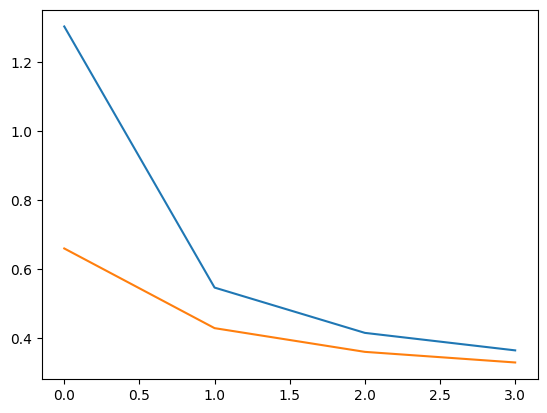

In [33]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

In [35]:
model.save("complete_save_model.keras")

In [37]:
model2 = keras.models.load_model("/content/complete_save_model.keras")

In [39]:
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,312 (1.16 MB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,542 (795.09 KB)

In [49]:
base_input = model.layers[0].input
base_output = model.layers[1].output
dense3= keras.layers.Dense(64)(base_output)
final_output = keras.layers.Dense(15)(dense3)

In [50]:
model3 = keras.Model(inputs=base_input, outputs=final_output)

In [51]:
model3.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,711 (428.56 KB)

 Trainable params: 109,711 (428.56 KB)

 Non-trainable params: 0 (0.00 B)